# Clasificar el Nivel de Riesgo
Se pretende estimar el riesgo ante una llamada a la línea 144, para esto se utiliza un modelo de Random Forest.

El mótivo de la elección de este modelo, es que el dataset cuenta una gran cantidad de variables *One-Hot*, además de no tener una variable objetivo.

Previamente, el dataset tratado con **Ingenieria de Atributos**, se creó una nueva columna objetivo a través de una formula que asignaba distintos pesos a las variables lógicas y categóricas con las que contamos, y le otorgaba un puntaj que representa el grado de violencia.

In [27]:
# Importación de Librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBRegressor
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, mean_squared_error, mean_absolute_error, r2_score
import joblib

In [ ]:
# Formula para determinar el riesgo de la llamada
def definir_riesgo(row):
    
    # Criterio de Riesgo Alto (2)
    if (row['tipo_de_violencia_fisica_si'] == 1 or row['tipo_de_violencia_sexual_si'] == 1) and row['vinculo_alto_riesgo'] == 1:
        return 2
    
    # Criterio de Riesgo Medio (1)
    elif row['score_tipos_violencia'] > 4 or row['score_modalidades_criticas'] > 2:
        return 1
    
    # Criterio de Riesgo Bajo (0)
    return 0

url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/data/processed/dataset_procesado.parquet"

# Recuperación del dataset procesado
print("Cargando dataset procesado...")

df = pd.read_parquet(url, engine="pyarrow")



Cargando dataset procesado...


In [7]:
# Llama a la función 'definir_riesgo()' para determinar el riesgo de la llamada
print("Calculando variable sintética de riesgo...")
df['nivel_riesgo'] = df.apply(definir_riesgo, axis=1)

# Nos quedamos únicamente con los riesgos Medio (1) y Alto (2)
df = df[df['nivel_riesgo'].isin([1, 2])].copy()

# Selección de Features y exclusión de Data Leakage
# Quitamos del mapa las variables que se uso para construir la formula matemática.
columnas_a_excluir = [
    'nivel_riesgo',
    'Fecha',
    'poblacion_provincia',
    'tipo_de_violencia_fisica_si',
    'tipo_de_violencia_sexual_si',
    'vinculo_alto_riesgo',
    'score_tipos_violencia',
    'score_modalidades_criticas',
    'interaccion_gravedad_domestica',
    'pandemia'
]

# Variable objetivo que el modelo debe aprender a predecir
Y_riesgo = df['nivel_riesgo']

# Se disminuye la cantidad de variables a las realmente importantes
features_importantes = [
    'edad_persona_en_situacion_de_violencia',
    'log_pobl_prov',
    'is_weekend',
    'tipo_de_violencia_psicologica_si',
    'tipo_de_violencia_simbolica_si',
    'tipo_de_violencia_economica_y_patrimonial_si',
    'tipo_de_violencia_domestica_si',
    'modalidad_de_violencia_institucional_si',
    'modalidad_de_violencia_laboral_si',
    'modalidad_de_violencia_otras_si',
    'vinculo_con_la_persona_agresora_pareja',
    'vinculo_con_la_persona_agresora_ex pareja',
    'vinculo_con_la_persona_agresora_otro',
    'vinculo_con_la_persona_agresora_otro familiar',
    'genero_persona_en_situacion_de_violencia_mujer',
    'genero_persona_en_situacion_de_violencia_varon',
    'genero_de_la_persona_agresora_varon',
    'genero_de_la_persona_agresora_mujer'
]

# Guarda en 'X_riesgo' las variables a utilizar.
X_excluidas = df.drop(columns=columnas_a_excluir, errors='ignore')
X_riesgo = X_excluidas[features_importantes].copy()

# Partición de datos - Split (80% entrenamiento y 20% testeo).
X_train, X_test, Y_train, Y_test = train_test_split(
    X_riesgo, Y_riesgo, test_size=0.2, random_state=42, stratify=Y_riesgo
)

Calculando variable sintética de riesgo...


In [15]:
# Configura e inicia la búsqueda de hiperparámetros con GridSearchCV.
print("Iniciando GridSearchCV para Random Forest...")
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, 15, None],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced']
}

rf_base = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=3,
    scoring='f1_macro',     # Busca maximizar la métrica 'f1_macro'
    n_jobs=-1
)
grid_search.fit(X_train, Y_train)

best_rf = grid_search.best_estimator_
print(f"\nMejores parámetros encontrados: {grid_search.best_params_}")



Iniciando GridSearchCV para Random Forest...

Mejores parámetros encontrados: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}


In [ ]:
joblib.dump(best_rf, "riesgo.joblib", compress=3)

['riesgo.joblib']


================ REPORTE DE CLASIFICACIÓN ================
              precision    recall  f1-score   support

       Medio       0.78      0.57      0.66      6227
        Alto       0.78      0.91      0.84     10749

    accuracy                           0.78     16976
   macro avg       0.78      0.74      0.75     16976
weighted avg       0.78      0.78      0.77     16976



,Métrica,Entrenamiento,Prueba
0,F1-Macro,0.785699,0.750425
1,Accuracy,0.813705,0.783930



Gráfica de importancia guardada como 'importancia_features_riesgo.png'


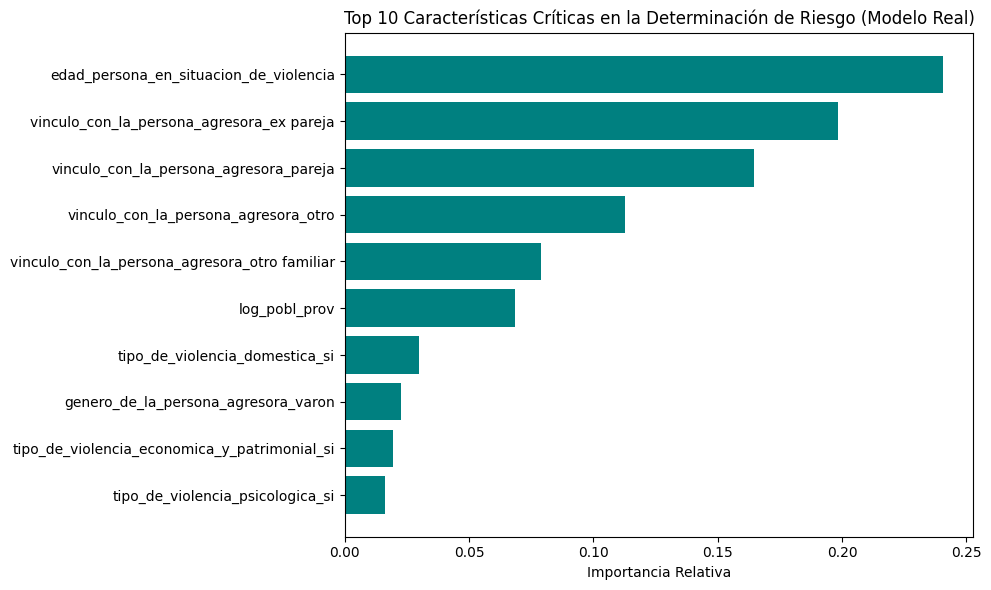

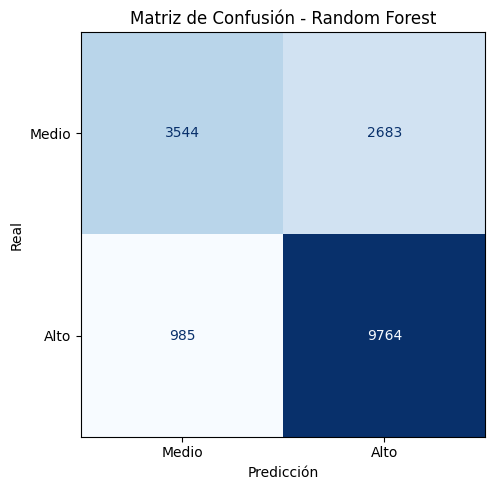

In [9]:
# Predicción y Evaluación del modelo
Y_pred = best_rf.predict(X_test)

print("\n================ REPORTE DE CLASIFICACIÓN ================")
print(classification_report(Y_test, Y_pred, labels=[1, 2], target_names=['Medio', 'Alto']))
print("==========================================================")

    
# Gráfica de importancia de variables
importances = best_rf.feature_importances_
indices = np.argsort(importances)[-10:] # Top 10 variables más 

# Ejemplo inspirado en la Sección 6 de la notebook para detectar overfitting
resultados_clf = pd.DataFrame({
    "Métrica": ["F1-Macro", "Accuracy"],
    "Entrenamiento": [
        classification_report(Y_train, best_rf.predict(X_train), output_dict=True)['macro avg']['f1-score'],
        best_rf.score(X_train, Y_train)
    ],
    "Prueba": [
        classification_report(Y_test, Y_pred, output_dict=True)['macro avg']['f1-score'],
        best_rf.score(X_test, Y_test)
    ]
})

display(resultados_clf)

plt.figure(figsize=(10, 6))
plt.title("Top 10 Características Críticas en la Determinación de Riesgo (Modelo Real)")
plt.barh(range(len(indices)), importances[indices], color='teal', align='center')
plt.yticks(range(len(indices)), [X_riesgo.columns[i] for i in indices])
plt.xlabel('Importancia Relativa')
plt.tight_layout()

plt.savefig('importancia_features_riesgo.png', dpi=300)
print("\nGráfica de importancia guardada como 'importancia_features_riesgo.png'")
plt.show()

# Matriz de confusión
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, Y_test, 
    display_labels=['Medio', 'Alto'], 
    cmap='Blues', colorbar=False, ax=ax
)
ax.set(title="Matriz de Confusión - Random Forest", xlabel="Predicción", ylabel="Real")
plt.tight_layout()
plt.savefig('matriz_confusion_rf.png', dpi=300)
plt.show()

los graficos...

# Estimar Demanda diaria
Nos pareció acertado al contar con el dataset, utilizarlo para estimar, a través de otro modelo, el volumen de llamadas para una fecha dada.

Esto debido 

La utilidad de esta predicción son las siguientes:
- Asignación de recursos
- Refuerzo de personal
- Logistica
- Análisis estadístico

Entre otras.

Elegimos XGBoost (eXtreme Gradient Boosting) para estimar la demanda diaria de llamadas (una variable continua) debido a su capacidad excepcional para capturar relaciones no lineales complejas, manejar patrones estacionales y ofrecer una alta velocidad de cómputo en datos estructurados.
A diferencia de los modelos lineales tradicionales, la demanda de llamadas en la línea 144 no se comporta de manera uniforme; está influenciada por picos estacionales, días festivos y variables categóricas complejas.

In [ ]:
print("\n--- Iniciando modelo XGBoost para Predicción de Volumen de Llamadas ---")
    
# Agrupa por fecha para obtener la cantidad de llamadas diarias.
df_volumen = df.groupby('Fecha').size().reset_index(name='volumen_llamadas')
df_volumen = df_volumen.sort_values('Fecha').reset_index(drop=True)

# Ingeniería de atributos temporales.
df_volumen['dia_semana'] = df_volumen['Fecha'].dt.dayofweek
df_volumen['mes'] = df_volumen['Fecha'].dt.month
df_volumen['dia'] = df_volumen['Fecha'].dt.day

# Crear rezagados (lags): el volumen de días anteriores ayuda a predecir el futuro.
df_volumen['lag_1'] = df_volumen['volumen_llamadas'].shift(1)  # Día anterior
df_volumen['lag_7'] = df_volumen['volumen_llamadas'].shift(7)  # Misma semana previa

# Elimina valores nulos generados por los lags.
df_volumen = df_volumen.dropna().reset_index(drop=True)

# Definir Features (X) y Target (Y).
features_volumen = ['dia_semana', 'mes', 'dia', 'lag_1', 'lag_7']
X_vol = df_volumen[features_volumen]
Y_vol = df_volumen['volumen_llamadas']

# Partición cronológica (80% pasado para entrenar, 20% futuro para testear)
train_size = int(len(X_vol) * 0.8)
X_train_vol, X_test_vol = X_vol.iloc[:train_size], X_vol.iloc[train_size:]
Y_train_vol, Y_test_vol = Y_vol.iloc[:train_size], Y_vol.iloc[train_size:]

# 6. Configurar GridSearchCV para entrenar XGBoost Regressor
print("Iniciando GridSearchCV para XGBoost Regressor...")
param_grid_xgb = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 6],
    'learning_rate': [0.01, 0.1]
}

xgb_base = XGBRegressor(random_state=42, n_jobs=-1)

# TimeSeriesSplit respeta el orden temporal para la validación cruzada
tscv = TimeSeriesSplit(n_splits=3)

grid_search_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    cv=tscv,
    scoring='neg_mean_absolute_error', # Mide el error absoluto medio negativo
    n_jobs=-1
)
grid_search_xgb.fit(X_train_vol, Y_train_vol)

best_xgb_reg = grid_search_xgb.best_estimator_
print(f"\nMejores parámetros encontrados para XGBoost: {grid_search_xgb.best_params_}")




--- Iniciando modelo XGBoost para Predicción de Volumen de Llamadas ---
Iniciando GridSearchCV para XGBoost Regressor...

Mejores parámetros encontrados para XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}


In [18]:
joblib.dump(best_xgb_reg, "volumen.joblib", compress=3)



['volumen.joblib']


================ EVALUACIÓN DE PREDICCIÓN DE VOLUMEN ==================
MAE (Error Absoluto Medio): 9.22 llamadas por día
RMSE (Raíz del Error Cuadrático Medio): 11.25
R² (Coeficiente de Determinación): -0.1467

Resumen Comparativo (Entrenamiento vs. Prueba):


,Métrica,Entrenamiento,Prueba
0,MAE,8.111,9.223
1,RMSE,10.495,11.251
2,R²,0.560,-0.147


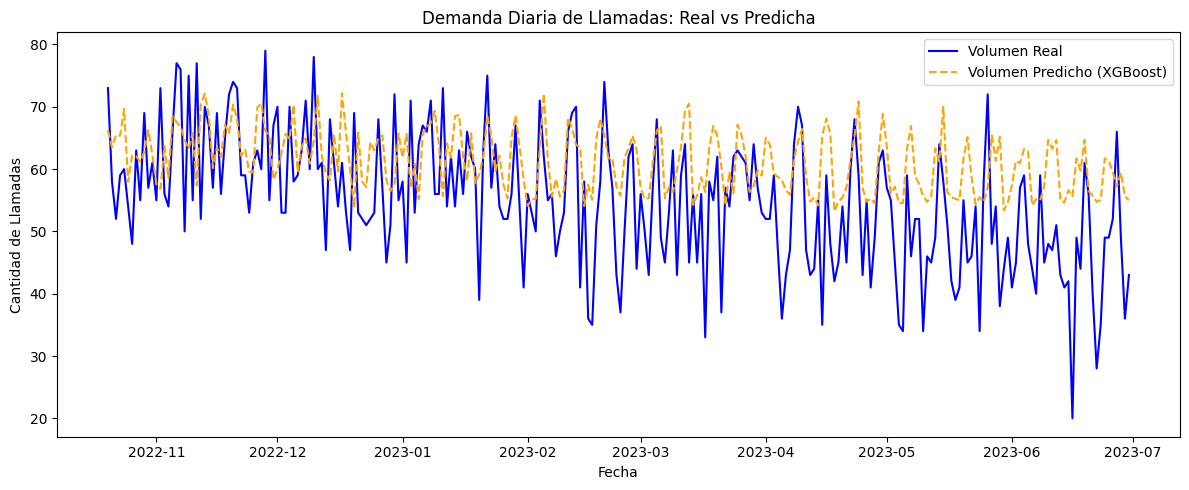

In [12]:
# Predicción y Evaluación
Y_pred_vol = best_xgb_reg.predict(X_test_vol)

mae = mean_absolute_error(Y_test_vol, Y_pred_vol)
rmse = np.sqrt(mean_squared_error(Y_test_vol, Y_pred_vol))
r2 = r2_score(Y_test_vol, Y_pred_vol)

print("\n================ EVALUACIÓN DE PREDICCIÓN DE VOLUMEN ==================")
print(f"MAE (Error Absoluto Medio): {mae:.2f} llamadas por día")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.2f}")
print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print("========================================================================")

# Comparación de las métricas
y_train_pred_vol = best_xgb_reg.predict(X_train_vol)

# Tabla comparativa de entrenamiento vs prueba (Inspirado en la Sección 6 de la notebook)
resultados_volumen = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Entrenamiento": [
        mean_absolute_error(Y_train_vol, y_train_pred_vol),
        np.sqrt(mean_squared_error(Y_train_vol, y_train_pred_vol)),
        r2_score(Y_train_vol, y_train_pred_vol)
    ],
    "Prueba": [
        mae,
        rmse,
        r2
    ]
})

print("\nResumen Comparativo (Entrenamiento vs. Prueba):")
display(resultados_volumen.round(3))

plt.figure(figsize=(12, 5))
plt.plot(df_volumen['Fecha'].iloc[train_size:], Y_test_vol, label='Volumen Real', color='blue')
plt.plot(df_volumen['Fecha'].iloc[train_size:], Y_pred_vol, label='Volumen Predicho (XGBoost)', color='orange', linestyle='--')
plt.title('Demanda Diaria de Llamadas: Real vs Predicha')
plt.xlabel('Fecha')
plt.ylabel('Cantidad de Llamadas')
plt.legend()
plt.tight_layout()
plt.savefig('prediccion_volumen_llamadas.png', dpi=300)
plt.show()

el grafico...

In [20]:
import io
import requests

# 1. Definir la URL directa del archivo .joblib o .pkl
url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/modelos/riesgo.joblib"

# 2. Descargar el archivo binario
respuesta = requests.get(url_modelo)
respuesta.raise_for_status()  # Lanza un error si la descarga falla

# 3. Cargar el modelo desde el búfer de memoria (BytesIO)
modelo_riesgo= joblib.load(io.BytesIO(respuesta.content))

Y_persistido_riesgo = modelo_riesgo.predict(X_test)

print(Y_persistido_riesgo)

[2 2 2 ... 1 2 2]


In [24]:
# 1. Definir la URL directa del archivo .joblib o .pkl
url_modelo = "https://github.com/UrielCasas/Clasificacion-Reportes_de_la_Linea-144/raw/main/modelos/volumen.joblib"

# 2. Descargar el archivo binario
respuesta = requests.get(url_modelo)
respuesta.raise_for_status()  # Lanza un error si la descarga falla

# 3. Cargar el modelo desde el búfer de memoria (BytesIO)
modelo_volumen= joblib.load(io.BytesIO(respuesta.content))

Y_persistido_volumen = modelo_volumen.predict(X_test_vol)

print(Y_persistido_volumen)

[66.24097  63.502136 65.49381  65.34338  69.67697  57.96019  62.224327
 62.05186  61.182613 62.75806  66.272675 62.278732 57.567886 56.84982
 63.73535  58.54736  68.47759  67.55348  66.80032  64.705666 63.23408
 65.80843  57.35788  70.36143  72.124    68.53595  60.15948  63.455956
 61.953957 67.0804   65.76678  70.360085 68.062035 62.138428 63.11461
 59.59306  59.442596 69.900276 70.518906 66.14163  65.280136 58.30831
 59.950466 62.589012 65.631645 64.8054   70.30857  59.492218 63.580307
 64.95286  60.885708 64.58912  71.76753  61.993607 59.375694 58.15163
 65.62132  59.59306  72.198555 65.7353   60.016087 53.813156 65.89962
 57.988533 57.098564 64.30761  62.99955  64.987236 65.40396  58.184547
 56.468018 57.481956 65.70992  61.857075 65.62633  56.991817 60.829464
 55.176247 65.657196 66.77277  67.36962  69.35229  63.925167 55.670734
 64.143486 61.826805 68.4906   68.69521  62.009224 58.061626 65.76533
 57.708626 59.167366 62.02587  68.56924  65.324524 59.654705 62.155014
 57.52991  55

In [25]:
print(Y_pred_vol)

[66.24097  63.502136 65.49381  65.34338  69.67697  57.96019  62.224327
 62.05186  61.182613 62.75806  66.272675 62.278732 57.567886 56.84982
 63.73535  58.54736  68.47759  67.55348  66.80032  64.705666 63.23408
 65.80843  57.35788  70.36143  72.124    68.53595  60.15948  63.455956
 61.953957 67.0804   65.76678  70.360085 68.062035 62.138428 63.11461
 59.59306  59.442596 69.900276 70.518906 66.14163  65.280136 58.30831
 59.950466 62.589012 65.631645 64.8054   70.30857  59.492218 63.580307
 64.95286  60.885708 64.58912  71.76753  61.993607 59.375694 58.15163
 65.62132  59.59306  72.198555 65.7353   60.016087 53.813156 65.89962
 57.988533 57.098564 64.30761  62.99955  64.987236 65.40396  58.184547
 56.468018 57.481956 65.70992  61.857075 65.62633  56.991817 60.829464
 55.176247 65.657196 66.77277  67.36962  69.35229  63.925167 55.670734
 64.143486 61.826805 68.4906   68.69521  62.009224 58.061626 65.76533
 57.708626 59.167366 62.02587  68.56924  65.324524 59.654705 62.155014
 57.52991  55